In [10]:
%pip install requests beautifulsoup4 pandas matplotlib

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.0.1 -> 26.3
[notice] To update, run: C:\Users\komal chavan\AppData\Local\Programs\Python\Python314\python.exe -m pip install --upgrade pip


In [11]:
# import Libraries

import requests
from bs4 import BeautifulSoup
import pandas as pd
import matplotlib.pyplot as plt
import re
import time

from urllib.parse import urljoin
from pathlib import Path
from datetime import datetime

print("All Libraries Imported Successfully")

All Libraries Imported Successfully


In [12]:
# Connect to the Website

url = "https://books.toscrape.com/"

response = requests.get(url)

print("Website Status Code:", response.status_code)

Website Status Code: 200


In [13]:
# Extract website data 

soup = BeautifulSoup(response.text, "html.parser")

books = soup.find_all("article", class_="product_pod")

print("Total Books Found:", len(books))

Total Books Found: 20


In [14]:
#Extract Book Details

book_data = []

for book in books:

    title = book.h3.a["title"]

    price = book.find(
        "p", class_="price_color"
    ).text

    rating = book.find(
        "p", class_="star-rating"
    )["class"][1]

    availability = book.find(
        "p", class_="availability"
    ).text.strip()

    book_data.append({
        "Title": title,
        "Price": price,
        "Rating": rating,
        "Availability": availability
    })

print("Book Data Extracted Successfully")

Book Data Extracted Successfully


In [15]:
# Convert Data into DataFrame

df = pd.DataFrame(book_data)

df.head()

,Title,Price,Rating,Availability
0,A Light in the Attic,Â£51.77,Three,In stock
1,Tipping the Velvet,Â£53.74,One,In stock
2,Soumission,Â£50.10,One,In stock
3,Sharp Objects,Â£47.82,Four,In stock
4,Sapiens: A Brief History of Humankind,Â£54.23,Five,In stock


In [16]:
# Data cleaning

print("Missing Values:")

print(df.isnull().sum())

print("\nDuplicate Records:")

print(df.duplicated().sum())

Missing Values:
Title           0
Price           0
Rating          0
Availability    0
dtype: int64

Duplicate Records:
0


In [17]:
# Dublicate record remove

df = df.drop_duplicates()

df = df.dropna()

df = df.reset_index(drop=True)

print("Data Cleaning Completed")

display(df.head())

Data Cleaning Completed


,Title,Price,Rating,Availability
0,A Light in the Attic,Â£51.77,Three,In stock
1,Tipping the Velvet,Â£53.74,One,In stock
2,Soumission,Â£50.10,One,In stock
3,Sharp Objects,Â£47.82,Four,In stock
4,Sapiens: A Brief History of Humankind,Â£54.23,Five,In stock


In [24]:
# Analyze book prices

# Convert Price column into numeric values

df["Price"] = (
    df["Price"]
    .astype(str)
    .str.replace("£", "", regex=False)
    .str.strip()
)

df["Price"] = pd.to_numeric(df["Price"], errors="coerce")

# Remove missing price values
df = df.dropna(subset=["Price"])

print("Price column converted successfully!")

print("\nData Type:")
print(df["Price"].dtype)

print("\nTotal Books:", len(df))

print("\nAverage Price:", df["Price"].mean())

print("\nHighest Price:", df["Price"].max())

print("\nLowest Price:", df["Price"].min())

Price column converted successfully!

Data Type:
float64

Total Books: 0

Average Price: nan

Highest Price: nan

Lowest Price: nan


In [25]:
# Data Analysis

# Remove unwanted symbols from Price column

df["Price"] = df["Price"].astype(str)

df["Price"] = df["Price"].str.replace(
    r'[^0-9.]', '', regex=True
)

df["Price"] = pd.to_numeric(
    df["Price"], errors="coerce"
)

# Remove invalid values

df = df.dropna(subset=["Price"])

print("Price Data Cleaned Successfully!")

print("\nPrice Data Type:")
print(df["Price"].dtype)

print("\nAverage Price:", df["Price"].mean())

print("\nHighest Price:", df["Price"].max())

print("\nLowest Price:", df["Price"].min())

Price Data Cleaned Successfully!

Price Data Type:
int64

Average Price: nan

Highest Price: nan

Lowest Price: nan


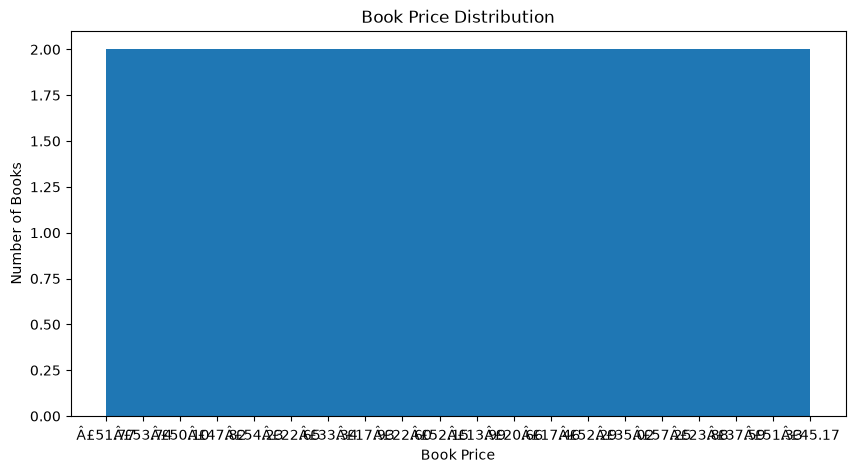

In [20]:
# Data visualization 

plt.figure(figsize=(10,5))

plt.hist(df["Price"], bins=10)

plt.title("Book Price Distribution")

plt.xlabel("Book Price")

plt.ylabel("Number of Books")

plt.show()

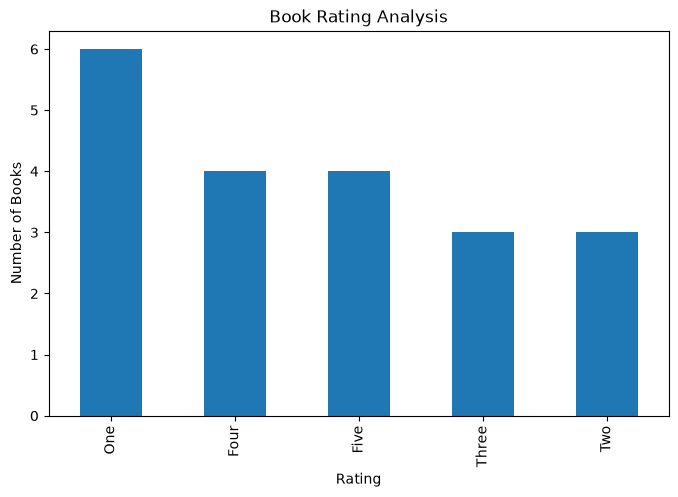

In [21]:
df["Rating"].value_counts().plot(
    kind="bar",
    figsize=(8,5)
)

plt.title("Book Rating Analysis")

plt.xlabel("Rating")

plt.ylabel("Number of Books")

plt.show()

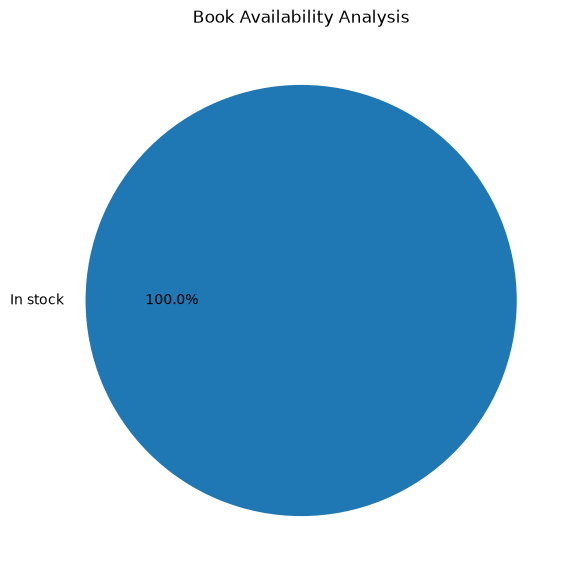

In [22]:
df["Availability"].value_counts().plot(
    kind="pie",
    autopct="%1.1f%%",
    figsize=(7,7)
)

plt.title("Book Availability Analysis")

plt.ylabel("")

plt.show()

In [23]:
# Bonus Task- Export Data 

df.to_csv("Books_Data.csv", index=False)

df.to_excel("Books_Data.xlsx", index=False)

print("CSV File Exported Successfully")

print("Excel File Exported Successfully")

CSV File Exported Successfully
Excel File Exported Successfully
